In [ ]:
import os
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

CSV_PATH = r"D:\Users\DEBJIT DAS\Outliers_MedBhasha\data\Annotated_Corpus.csv"
OUTPUT_DIR = "./analytics_output"
CLUSTER_FILE = "../clustering/clustering_output/clinical_note_clusters.csv"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [7]:
df = pd.read_csv(CSV_PATH, dtype=str, keep_default_na=False)
required = {"note_id", "token", "tag"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

df = df[["note_id", "token", "tag"]].copy()
for col in ["note_id", "token", "tag"]:
    df[col] = df[col].astype(str).str.strip()

print("CSV rows:", len(df))
print("Unique note IDs:", df["note_id"].nunique())
print("Blank note IDs:", (df["note_id"] == "").sum())
print("Blank tokens:", (df["token"] == "").sum())
print("Blank tags:", (df["tag"] == "").sum())
display(df.head(10))

CSV rows: 10743
Unique note IDs: 534
Blank note IDs: 0
Blank tokens: 0
Blank tags: 0


,note_id,token,tag
0,syn001,রোগীর,O
1,syn001,গত,B-TEMPORAL
2,syn001,তিন,I-TEMPORAL
3,syn001,দিন,I-TEMPORAL
4,syn001,ধরে,I-TEMPORAL
5,syn001,জ্বর,B-SYMPTOM
6,syn001,রয়েছে,O
7,syn001,এবং,O
8,syn001,বুক,B-BODY_SITE
9,syn001,অস্বস্তি,O


In [6]:
valid_df = df[(df.note_id != "") & (df.token != "")].copy()

notes_df = (
    valid_df.groupby("note_id", sort=False)
    .agg(tokens=("token", list), tags=("tag", list), token_count=("token", "size"))
    .reset_index()
)
notes_df["text"] = notes_df["tokens"].apply(lambda x: " ".join(x))
notes_df["character_count"] = notes_df["text"].str.len()

basic_stats = pd.DataFrame({
    "Metric": [
        "Total CSV rows", "Usable token rows", "Unique clinical notes",
        "Unique tokens (vocabulary size)", "Average tokens per note",
        "Median tokens per note", "Shortest note (tokens)", "Longest note (tokens)"
    ],
    "Value": [
        len(df), len(valid_df), notes_df.note_id.nunique(),
        valid_df.token.nunique(), round(notes_df.token_count.mean(), 2),
        round(notes_df.token_count.median(), 2), int(notes_df.token_count.min()),
        int(notes_df.token_count.max())
    ]
})
display(basic_stats)
display(notes_df[["note_id", "token_count", "character_count", "text"]].head())

,Metric,Value
0,Total CSV rows,10743.00
1,Usable token rows,10743.00
2,Unique clinical notes,534.00
3,Unique tokens (vocabulary size),646.00
4,Average tokens per note,20.12
5,Median tokens per note,16.00
6,Shortest note (tokens),6.00
7,Longest note (tokens),87.00


,note_id,token_count,character_count,text
0,syn001,12,57,রোগীর গত তিন দিন ধরে জ্বর রয়েছে এবং বুক অস্বস...
1,syn002,12,72,রোগীর ডায়াবেটিস ধরা পড়েছে । বর্তমানে মেটফরমি...
2,syn003,14,70,পরীক্ষা হিসেবে রক্ত পরীক্ষা করা হয়েছে এবং ফল ...
3,syn004,14,65,রোগী বুক ব্যথা নেই বলেছেন । সমস্যাটি গত তিন দি...
4,syn005,16,77,"রোগীর জ্বর কমেছে , তবে গত তিন দিন ধরে পুনরায় ..."


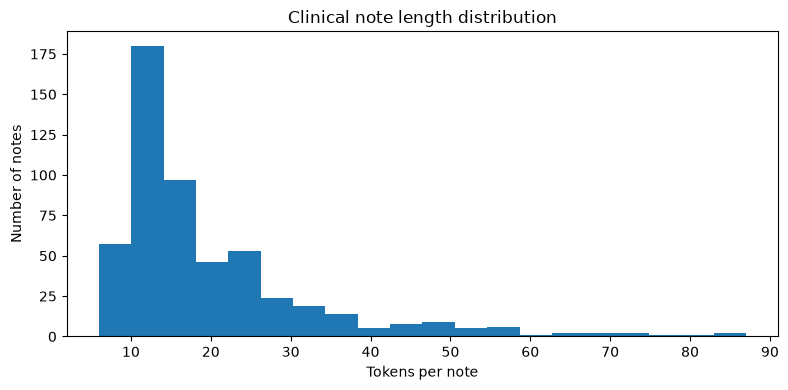

In [8]:
plt.figure(figsize=(8, 4))
plt.hist(notes_df["token_count"], bins=20)
plt.xlabel("Tokens per note")
plt.ylabel("Number of notes")
plt.title("Clinical note length distribution")
plt.tight_layout()
plt.show()

,tag,count,percentage
0,O,6881,64.05
1,I-TEMPORAL,709,6.60
2,B-SYMPTOM,530,4.93
3,B-TEMPORAL,423,3.94
4,B-TEST,329,3.06
5,I-TEST,267,2.49
6,B-TEST_RESULT,244,2.27
7,B-NEGATION_UNCERTAINTY,219,2.04
8,B-DIAGNOSIS,169,1.57
9,B-MEDICATION,166,1.55


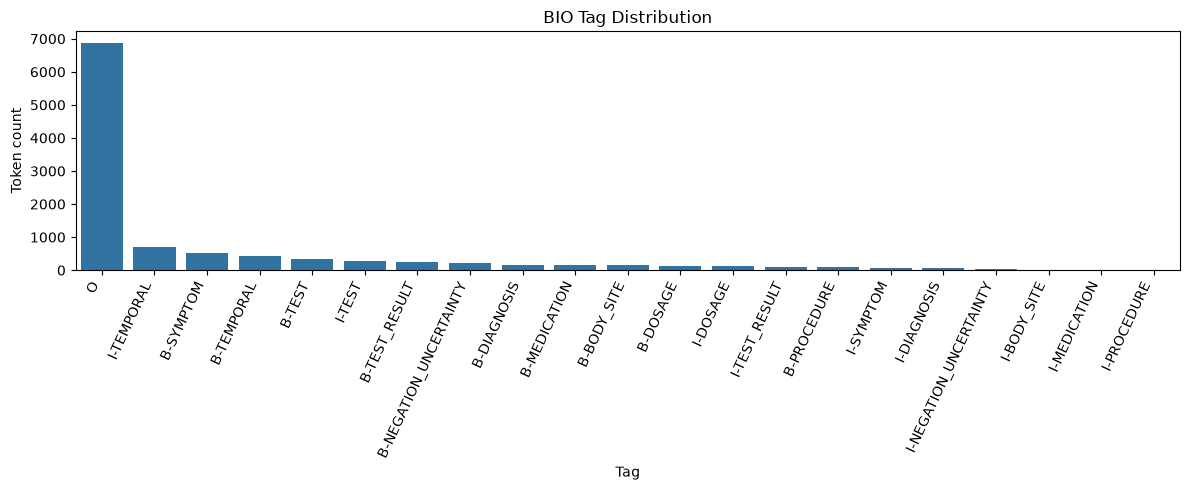

In [9]:
tag_counts = valid_df["tag"].value_counts().rename_axis("tag").reset_index(name="count")
tag_counts["percentage"] = (tag_counts["count"] / tag_counts["count"].sum() * 100).round(2)
display(tag_counts)

plt.figure(figsize=(12, 5))
sns.barplot(data=tag_counts, x="tag", y="count")
plt.title("BIO Tag Distribution")
plt.xlabel("Tag")
plt.ylabel("Token count")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

In [10]:
ENTITY_TYPES = [
    "DIAGNOSIS", "SYMPTOM", "MEDICATION", "DOSAGE", "TEST",
    "TEST_RESULT", "BODY_SITE", "PROCEDURE", "TEMPORAL",
    "NEGATION_UNCERTAINTY"
]
entity_counts = Counter()
sequence_issues = []

for note_id, group in valid_df.groupby("note_id", sort=False):
    active_entity = None
    for row_index, tag in zip(group.index, group.tag):
        if tag == "O":
            active_entity = None
            continue
        if "-" not in tag:
            sequence_issues.append((note_id, row_index, tag, "Malformed tag"))
            active_entity = None
            continue
        prefix, entity = tag.split("-", 1)
        if entity not in ENTITY_TYPES or prefix not in {"B", "I"}:
            sequence_issues.append((note_id, row_index, tag, "Unsupported BIO tag"))
            active_entity = None
        elif prefix == "B":
            entity_counts[entity] += 1
            active_entity = entity
        elif active_entity != entity:
            sequence_issues.append((note_id, row_index, tag, "I-tag does not continue matching entity"))
            active_entity = None

entity_summary = pd.DataFrame([
    {"entity": e, "mention_count": entity_counts.get(e, 0)}
    for e in ENTITY_TYPES
])
total_mentions = max(entity_summary.mention_count.sum(), 1)
entity_summary["percentage"] = (entity_summary.mention_count / total_mentions * 100).round(2)
display(entity_summary.sort_values("mention_count", ascending=False))
print("BIO sequence issues:", len(sequence_issues))
for issue in sequence_issues[:20]:
    print(issue)

,entity,mention_count,percentage
1,SYMPTOM,530,21.70
8,TEMPORAL,423,17.32
4,TEST,329,13.47
5,TEST_RESULT,244,9.99
9,NEGATION_UNCERTAINTY,219,8.97
0,DIAGNOSIS,169,6.92
2,MEDICATION,166,6.80
6,BODY_SITE,153,6.27
3,DOSAGE,127,5.20
7,PROCEDURE,82,3.36


BIO sequence issues: 0


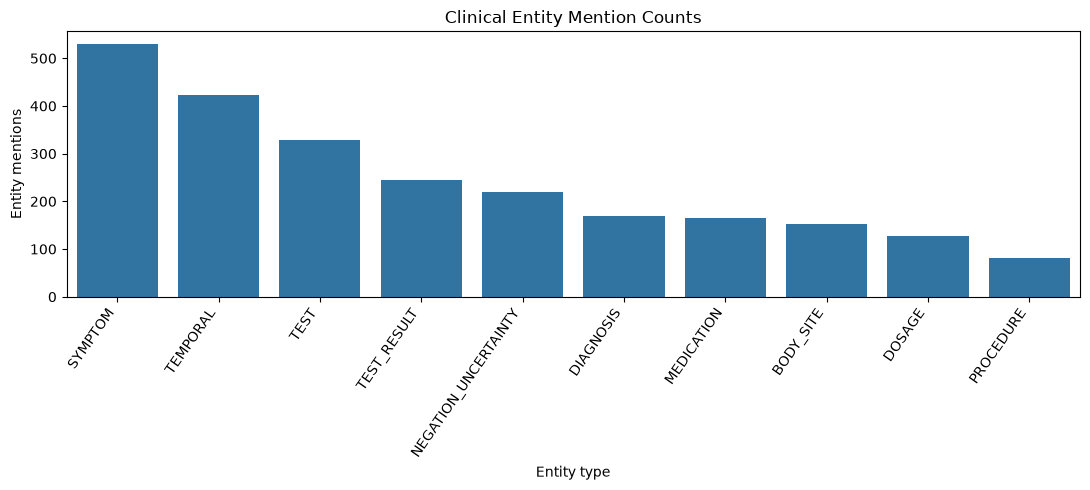

In [11]:
plot_data = entity_summary.sort_values("mention_count", ascending=False)
plt.figure(figsize=(11, 5))
sns.barplot(data=plot_data, x="entity", y="mention_count")
plt.title("Clinical Entity Mention Counts")
plt.xlabel("Entity type")
plt.ylabel("Entity mentions")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.show()

,token,frequency
0,।,1228
1,",",362
2,হয়েছে,352
3,করা,195
4,রোগীর,186
5,পরীক্ষা,155
6,রোগী,149
7,দিন,145
8,এর,145
9,:,139


C:\Users\DEBJIT   DAS\AppData\Local\Temp\ipykernel_31868\135018982.py:7: UserWarning: Glyph 2404 (\N{DEVANAGARI DANDA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\DEBJIT   DAS\AppData\Local\Temp\ipykernel_31868\135018982.py:7: UserWarning: Glyph 2489 (\N{BENGALI LETTER HA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\DEBJIT   DAS\AppData\Local\Temp\ipykernel_31868\135018982.py:7: UserWarning: Glyph 2479 (\N{BENGALI LETTER YA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\DEBJIT   DAS\AppData\Local\Temp\ipykernel_31868\135018982.py:7: UserWarning: Glyph 2459 (\N{BENGALI LETTER CHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\DEBJIT   DAS\AppData\Local\Temp\ipykernel_31868\135018982.py:7: UserWarning: Glyph 2453 (\N{BENGALI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\DEBJIT   DAS\AppData\Local\Temp\ipykernel_31868\135018982.py:7: UserWarning: Glyph 2480 (\N{BENGALI LETTER RA})

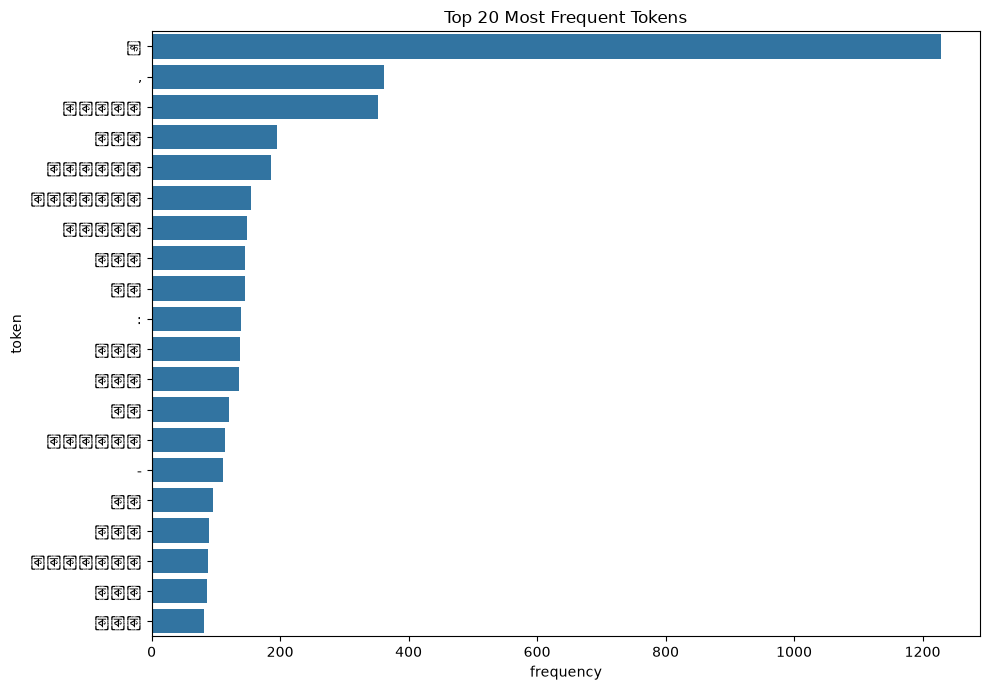

In [12]:
token_counts = valid_df["token"].value_counts().head(30).rename_axis("token").reset_index(name="frequency")
display(token_counts)

plt.figure(figsize=(10, 7))
sns.barplot(data=token_counts.head(20), y="token", x="frequency")
plt.title("Top 20 Most Frequent Tokens")
plt.tight_layout()
plt.show()

,DIAGNOSIS,SYMPTOM,MEDICATION,DOSAGE,TEST,TEST_RESULT,BODY_SITE,PROCEDURE,TEMPORAL,NEGATION_UNCERTAINTY
DIAGNOSIS,169,91,61,53,83,54,13,35,89,80
SYMPTOM,91,321,78,54,116,89,118,46,212,133
MEDICATION,61,78,147,112,73,43,26,22,101,66
DOSAGE,53,54,112,112,65,37,19,16,80,41
TEST,83,116,73,65,267,188,54,38,135,79
TEST_RESULT,54,89,43,37,188,188,46,20,99,51
BODY_SITE,13,118,26,19,54,46,146,8,74,56
PROCEDURE,35,46,22,16,38,20,8,82,47,27
TEMPORAL,89,212,101,80,135,99,74,47,281,104
NEGATION_UNCERTAINTY,80,133,66,41,79,51,56,27,104,184


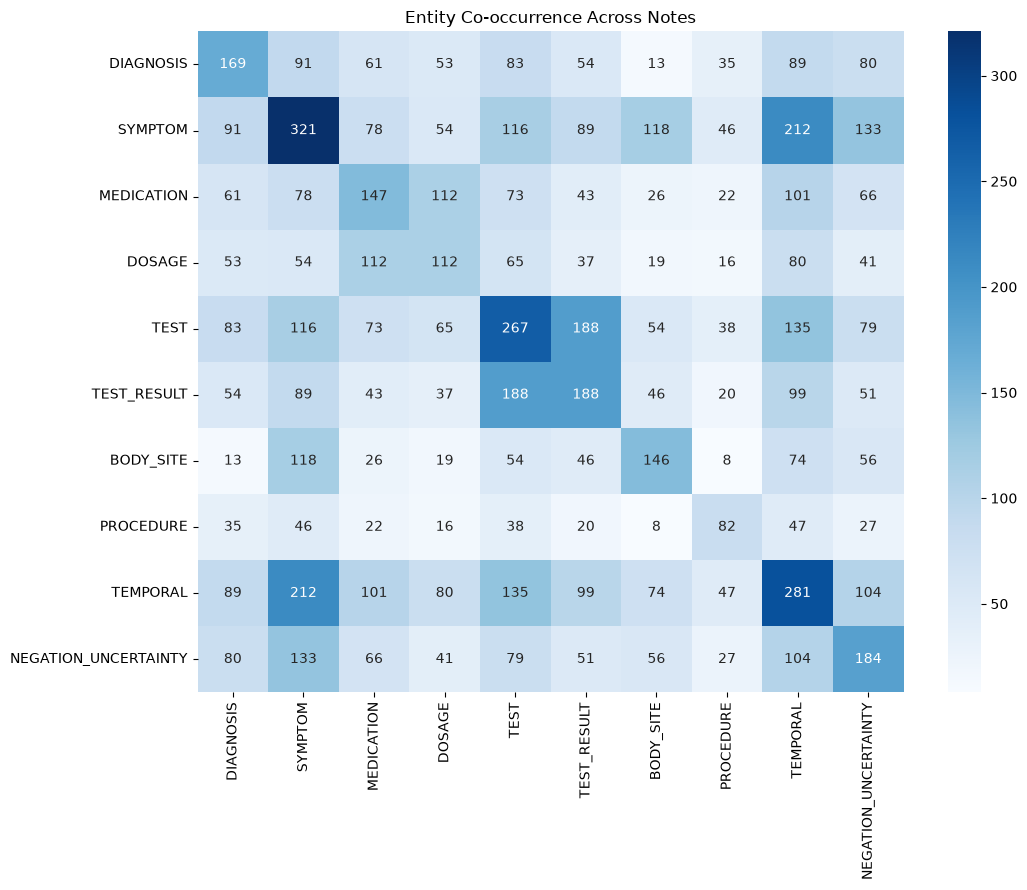

In [13]:
note_entity_sets = {}
for note_id, group in valid_df.groupby("note_id", sort=False):
    note_entity_sets[note_id] = {
        tag[2:] for tag in group.tag
        if tag.startswith("B-") and tag[2:] in ENTITY_TYPES
    }

cooccurrence = pd.DataFrame(0, index=ENTITY_TYPES, columns=ENTITY_TYPES, dtype=int)
for found in note_entity_sets.values():
    for entity in found:
        cooccurrence.loc[entity, entity] += 1
    for a, b in combinations(sorted(found), 2):
        cooccurrence.loc[a, b] += 1
        cooccurrence.loc[b, a] += 1

display(cooccurrence)
plt.figure(figsize=(11, 9))
sns.heatmap(cooccurrence, annot=True, fmt="d", cmap="Blues")
plt.title("Entity Co-occurrence Across Notes")
plt.tight_layout()
plt.show()

In [14]:
note_entity_counts = Counter()
for found in note_entity_sets.values():
    note_entity_counts.update(found)

entity_note_summary = pd.DataFrame([
    {
        "entity": entity,
        "notes_containing_entity": note_entity_counts.get(entity, 0),
        "percentage_of_notes": round(note_entity_counts.get(entity, 0) / max(len(notes_df), 1) * 100, 2)
    }
    for entity in ENTITY_TYPES
]).sort_values("notes_containing_entity", ascending=False)

display(entity_note_summary)

,entity,notes_containing_entity,percentage_of_notes
1,SYMPTOM,321,60.11
8,TEMPORAL,281,52.62
4,TEST,267,50.00
5,TEST_RESULT,188,35.21
9,NEGATION_UNCERTAINTY,184,34.46
0,DIAGNOSIS,169,31.65
2,MEDICATION,147,27.53
6,BODY_SITE,146,27.34
3,DOSAGE,112,20.97
7,PROCEDURE,82,15.36


In [18]:
basic_stats.to_csv(os.path.join(OUTPUT_DIR, "corpus_basic_statistics.csv"), index=False, encoding="utf-8-sig")
tag_counts.to_csv(os.path.join(OUTPUT_DIR, "tag_distribution.csv"), index=False, encoding="utf-8-sig")
entity_summary.to_csv(os.path.join(OUTPUT_DIR, "entity_frequency.csv"), index=False, encoding="utf-8-sig")
entity_note_summary.to_csv(os.path.join(OUTPUT_DIR, "entity_note_frequency.csv"), index=False, encoding="utf-8-sig")
token_counts.to_csv(os.path.join(OUTPUT_DIR, "top_tokens.csv"), index=False, encoding="utf-8-sig")
cooccurrence.to_csv(os.path.join(OUTPUT_DIR, "entity_cooccurrence.csv"), encoding="utf-8-sig")

report = [
    "MedBhasha Bengali Clinical Corpus Analytics",
    "=" * 48,
    "",
    "BASIC STATISTICS",
    basic_stats.to_string(index=False),
    "",
    "ENTITY FREQUENCY",
    entity_summary.sort_values("mention_count", ascending=False).to_string(index=False),
    "",
    f"BIO sequence issues detected: {len(sequence_issues)}",
]
report_path = os.path.join(OUTPUT_DIR, "analytics_report.txt")
with open(report_path, "w", encoding="utf-8") as f:
    f.write("\n".join(report))

print("Saved analytics files to:", os.path.abspath(OUTPUT_DIR))
print("Report:", os.path.abspath(report_path))

Saved analytics files to: d:\Users\DEBJIT DAS\MedBhasha-Resources\analytics_output
Report: d:\Users\DEBJIT DAS\MedBhasha-Resources\analytics_output\analytics_report.txt
